# Multinomial logit with JAX derivatives and GALAHAD

A custom criterion can obtain exact derivatives by automatic differentiation.
This example estimates a four-category multinomial logit, with the last category
normalized to zero. JAX supplies a scalar average negative log-likelihood,
gradient and full Hessian; GALAHAD supplies trust-region or cubic-regularized
steps. JAX is an optional dependency and is not imported by the core library.

With category $K$ as the reference,
$$P(y_i=k\mid x_i)=\frac{\exp(x_i^Tb_k)}{1+\sum_{j<K}\exp(x_i^Tb_j)},\qquad b_K=0.$$
The reference normalization is necessary for identification of the coefficients.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1009)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from time import perf_counter
from scipy.special import softmax
from galahad_econometrics import Criterion, tru, arc, check_derivatives

n, features, K = 2500, 4, 4
X = np.column_stack([np.ones(n), rng.normal(size=(n, features))])
p = X.shape[1]
true_free = .35*rng.normal(size=(p, K-1))
true_full = np.column_stack([true_free, np.zeros(p)])
probability = softmax(X @ true_full, axis=1)
y = np.array([rng.choice(K, p=row) for row in probability])
X_jax, y_jax = jnp.asarray(X), jnp.asarray(y)

print("JAX version:", jax.__version__, "backend:", jax.default_backend(),
      "float64 enabled:", jax.config.read("jax_enable_x64"))

JAX version: 0.12.0.1 backend: cpu float64 enabled: True


## Specify the likelihood once

The parameter vector is the row-major flattening of the `p × (K-1)` free
coefficient matrix. The reference category is appended inside the likelihood.
`log_softmax` avoids exponentiating and then taking logs of small probabilities.
All derivatives are in float64, matching the native solver's numerical precision.

In [3]:
def loss(params):
    free = params.reshape(p, K-1)
    full = jnp.column_stack([free, jnp.zeros(p)])
    log_prob = jax.nn.log_softmax(X_jax @ full, axis=1)
    return -jnp.mean(log_prob[jnp.arange(n), y_jax])

jax_fun = jax.jit(loss)
jax_grad = jax.jit(jax.grad(loss))
jax_hess = jax.jit(jax.hessian(loss))
criterion = Criterion(fun=lambda b: float(jax_fun(jnp.asarray(b))),
                      grad=lambda b: np.asarray(jax_grad(jnp.asarray(b)), dtype=np.float64),
                      hess=lambda b: np.asarray(jax_hess(jnp.asarray(b)), dtype=np.float64))
start = np.zeros(p*(K-1))

# Compilation is synchronized and measured separately from the solver calls.
started = perf_counter()
for function in [jax_fun, jax_grad, jax_hess]:
    function(jnp.asarray(start)).block_until_ready()
compilation_seconds = perf_counter()-started
checks = check_derivatives(criterion, .1*rng.normal(size=start.size))
assert max(checks.values()) < 1e-6
print(f"Initial JIT compilation and warm-up: {compilation_seconds:.3f} seconds")
checks

Initial JIT compilation and warm-up: 0.211 seconds


{'gradient_error': 1.5753294502207638e-11,
 'hessian_error': 8.604673966622692e-12}

## Solve with the same criterion

The table reports a single post-compilation solve for each method, not an average
runtime benchmark. Coefficient RMSE is computed over the 15 free coefficients;
it excludes the normalized reference category. Classification accuracy averages
correct predictions over all 2,500 training observations.

In [4]:
results, estimates, rows = {}, {}, []
for name, module in [("TRU", tru), ("ARC", arc)]:
    result = module.solve(criterion, start, trace=True)
    assert result.success, result.message
    free = result.x.reshape(p, K-1)
    full = np.column_stack([free, np.zeros(p)])
    predicted_probability = softmax(X @ full, axis=1)
    assert np.allclose(predicted_probability.sum(axis=1), 1.)
    # Independent analytic gradient check of the autodiff callback at the fit.
    residual = predicted_probability[:, :K-1] - np.eye(K)[y, :K-1]
    analytic_gradient = (X.T @ residual/n).ravel()
    assert np.max(np.abs(analytic_gradient-criterion.grad(result.x))) < 1e-10
    assert result.fun < np.log(K)
    results[name], estimates[name] = result, full
    rows.append({"solver": name, "objective": result.fun, "gradient norm": result.optimality,
                 "single solve seconds": result.seconds,
                 "free coefficient RMSE": np.sqrt(np.mean((free-true_free)**2)),
                 "training accuracy": np.mean(predicted_probability.argmax(axis=1)==y),
                 "native status": result.status})
assert np.max(np.abs(results["TRU"].x-results["ARC"].x)) < 2e-5
pd.DataFrame(rows).set_index("solver")

,objective,gradient norm,single solve seconds,free coefficient RMSE,training accuracy,native status
solver,,,,,,
TRU,1.1995,6.5147e-15,0.026387,0.07596,0.442,0
ARC,1.1995,4.4917e-14,0.010875,0.07596,0.442,0


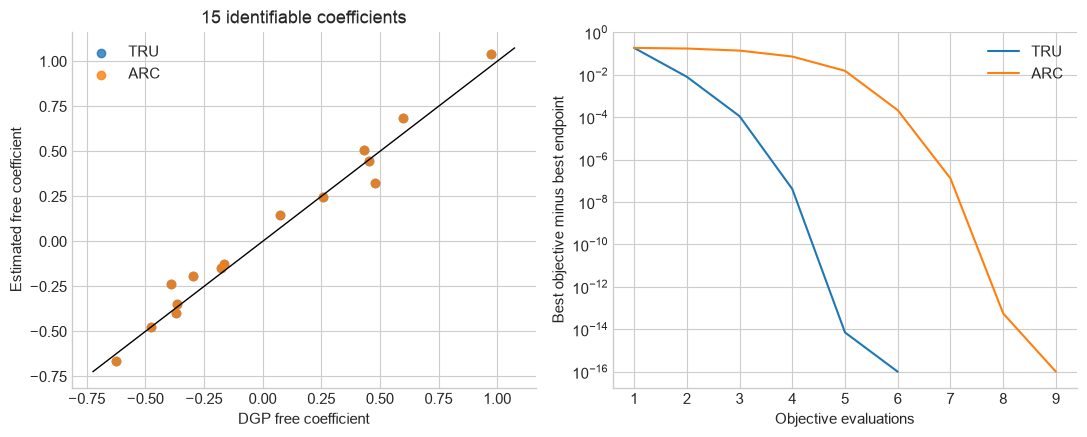

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, full in estimates.items():
    axes[0].scatter(true_free.ravel(), full[:, :K-1].ravel(), label=name, alpha=.8)
lo, hi = true_free.min()-.1, true_free.max()+.1
axes[0].plot([lo, hi], [lo, hi], color="black", linewidth=1)
axes[0].set(xlabel="DGP free coefficient", ylabel="Estimated free coefficient", title="15 identifiable coefficients")
axes[0].legend()
reference = min(result.fun for result in results.values())
for name, result in results.items():
    values = np.array([point.objective for point in result.history])
    axes[1].semilogy(np.arange(1, len(values)+1), np.maximum(np.minimum.accumulate(values)-reference, 1e-16),
                     label=name)
axes[1].set(xlabel="Objective evaluations", ylabel="Best objective minus best endpoint")
axes[1].legend()
fig.tight_layout()
plt.show()

This custom objective returns an optimization result, rather than the binary-logit
estimator's inference interface. The notebook demonstrates how to extend the
criterion API; it does not add a multinomial estimator class or automatic
covariance estimation to the library. Dense Hessians make this approach suitable
for moderate parameter dimensions. JIT compilation and device-to-host callback
costs remain relevant when assessing performance.